# NLP - Natural language Processing

In [22]:
sentence = "My organisation name is Deloitte. It is too far from my hometown bankura"
lowered_sentence = sentence.lower()
print(lowered_sentence)

my organisation name is deloitte. it is too far from my hometown bankura


In [23]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/souvikmaji/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [24]:
en_stopwords = stopwords.words('english')
print(en_stopwords)

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

In [25]:
en_stopwords.append("my")
no_stopwords = [word for word in lowered_sentence.split() if word not in en_stopwords]
sentence_no_stopwords = ' '.join(no_stopwords)
print(sentence_no_stopwords)

organisation name deloitte. far hometown bankura


In [26]:
import re
customer_service = [
    "Souvik contacted customer service about his account.",
    "Shouvik requested help with resetting the password, he quickly adapted",
    "The representative assisted him with the billing issue.",
    "Customer service followed up with Shouvik the next day, is it done ?"
]

search_pattern = r"Sh?ouvik"
find_pattern = r"^S"
pipe_pattern = r"(request|assist)ed"
no_punctuation_pattern = r"[^\w\s]"     # means find anything which is not a word or not a whitespace

souvik_reviews = []
for review in customer_service:
    if (re.search(pipe_pattern, review)):
        souvik_reviews.append(review)

# print(souvik_reviews)

no_punctuation_sentence = []
for review in customer_service:
    no_punc_string = re.sub(no_punctuation_pattern, "", review)
    no_punctuation_sentence.append(no_punc_string)
print(no_punctuation_sentence)


['Souvik contacted customer service about his account', 'Shouvik requested help with resetting the password he quickly adapted', 'The representative assisted him with the billing issue', 'Customer service followed up with Shouvik the next day is it done ']


# Tokenization

In [27]:
import nltk
nltk.download('punkt_tab')
from nltk.tokenize import word_tokenize, sent_tokenize

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/souvikmaji/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [34]:
sentences = "Her cat's name is Luna. Her dog's name is Max"

In [35]:
sent_tokenize(sentences)

["Her cat's name is Luna.", "Her dog's name is Max"]

In [36]:
word_tokenize(sentences)

['Her',
 'cat',
 "'s",
 'name',
 'is',
 'Luna',
 '.',
 'Her',
 'dog',
 "'s",
 'name',
 'is',
 'Max']

# Standardisation - Stemming and Lemmatization
### Stemming - reduce english words to a simpler base. but sometimes it creates a base word which doesn't have any meaning.
### Lemmatization - Advance version of Stemming where the base word will always be a meaningful and gramartically correct word.

In [46]:
from nltk.stem import PorterStemmer
# PorterStemmer is a classic role-based algorithm that reduce english words to a simpler base.

nltk.download('wordnet')
from nltk.stem import WordNetLemmatizer

[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/souvikmaji/nltk_data...


In [47]:
ps= PorterStemmer()
lm = WordNetLemmatizer()

In [49]:
connect_tokens = ['connecting', 'connected', 'connectivity', 'connect', 'connects', 'connector', 'connectors', 'like', 'better', 'worse']

In [53]:
print("Stemmetize\n")
for t in connect_tokens:
    print(t, ": ", ps.stem(t))
print("\nLemmatize\n")
for t in connect_tokens:
    print(t, ": ", lm.lemmatize(t))

Stemmetize

connecting :  connect
connected :  connect
connectivity :  connect
connect :  connect
connects :  connect
connector :  connector
connectors :  connector
like :  like
better :  better
worse :  wors

Lemmatize

connecting :  connecting
connected :  connected
connectivity :  connectivity
connect :  connect
connects :  connects
connector :  connector
connectors :  connector
like :  like
better :  better
worse :  worse


# N-Grams
### Helps us to analyze not just individual words but also the relationship between neighboring words

In [54]:
import nltk
import pandas as pd 
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [78]:
paragraph = "AI systems rely heavily on massive amounts of data to achieve effective learning. When engineers train these AI systems, they feed data into complex neural models so that the learning process can begin. As the AI encounters more data, the underlying models adapt, which dramatically improves the accuracy of their learning. Ultimately, the success of any AI depends entirely on the quality of that data and how well the models can sustain continuous learning over time."
no_pun_paragraph = re.sub(no_punctuation_pattern, "", paragraph)
word_tokens = word_tokenize(no_pun_paragraph)

print(word_tokens)

['AI', 'systems', 'rely', 'heavily', 'on', 'massive', 'amounts', 'of', 'data', 'to', 'achieve', 'effective', 'learning', 'When', 'engineers', 'train', 'these', 'AI', 'systems', 'they', 'feed', 'data', 'into', 'complex', 'neural', 'models', 'so', 'that', 'the', 'learning', 'process', 'can', 'begin', 'As', 'the', 'AI', 'encounters', 'more', 'data', 'the', 'underlying', 'models', 'adapt', 'which', 'dramatically', 'improves', 'the', 'accuracy', 'of', 'their', 'learning', 'Ultimately', 'the', 'success', 'of', 'any', 'AI', 'depends', 'entirely', 'on', 'the', 'quality', 'of', 'that', 'data', 'and', 'how', 'well', 'the', 'models', 'can', 'sustain', 'continuous', 'learning', 'over', 'time']


In [85]:
unigrams = (pd.Series(nltk.ngrams(word_tokens, 1)).value_counts())
print(unigrams[:11])

(the,)         7
(AI,)          4
(of,)          4
(data,)        4
(learning,)    4
(models,)      3
(systems,)     2
(on,)          2
(that,)        2
(can,)         2
(rely,)        1
Name: count, dtype: int64


Text(0.5, 1.0, '10 most frequently occuring unigrams')

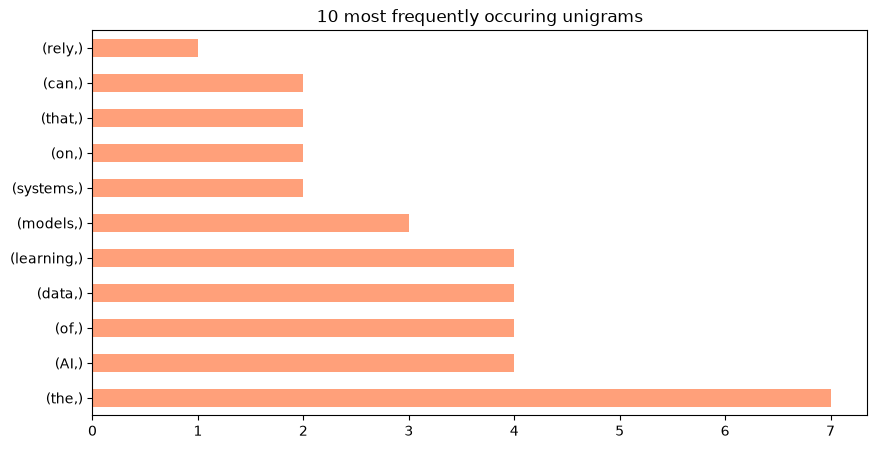

In [86]:
unigrams[:11].plot.barh(color="lightsalmon", width=.5, figsize=(10,5))
plt.title("10 most frequently occuring unigrams")

In [89]:
bigrams = (pd.Series(nltk.ngrams(word_tokens, 2)).value_counts())
print(bigrams[:10])

trigrams = (pd.Series(nltk.ngrams(word_tokens, 3)).value_counts())
print(trigrams[:10])

(AI, systems)         2
(systems, rely)       1
(rely, heavily)       1
(heavily, on)         1
(on, massive)         1
(massive, amounts)    1
(amounts, of)         1
(of, data)            1
(data, to)            1
(to, achieve)         1
Name: count, dtype: int64
(AI, systems, rely)         1
(systems, rely, heavily)    1
(rely, heavily, on)         1
(heavily, on, massive)      1
(on, massive, amounts)      1
(massive, amounts, of)      1
(amounts, of, data)         1
(of, data, to)              1
(data, to, achieve)         1
(to, achieve, effective)    1
Name: count, dtype: int64
